In [1]:
# Experiment 06 — Two-Qubit Operations: CNOT, Phase and SWAP

In [7]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
import numpy as np

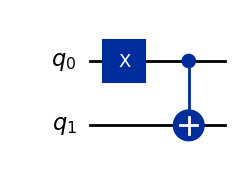

CNOT Statevector: [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
Probabilities: {np.str_('11'): np.float64(1.0)}


In [8]:
# Create a two-qubit circuit
qc_cnot = QuantumCircuit(2)

# Set qubit 0 to |1> and apply CNOT
qc_cnot.x(0)
qc_cnot.cx(0, 1)

# Display the circuit
display(qc_cnot.draw("mpl"))

# Show the output state
state_cnot = Statevector.from_instruction(qc_cnot)

print("CNOT Statevector:", state_cnot.data)
print("Probabilities:", state_cnot.probabilities_dict())

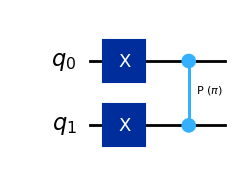

Controlled-Phase Statevector: [ 0.+0.0000000e+00j  0.+0.0000000e+00j  0.+0.0000000e+00j
 -1.+1.2246468e-16j]
Probabilities: {np.str_('11'): np.float64(1.0)}


In [9]:
# Create a two-qubit circuit
qc_phase = QuantumCircuit(2)

# Prepare the |11> state
qc_phase.x(0)
qc_phase.x(1)

# Apply a controlled phase of pi radians
qc_phase.cp(np.pi, 0, 1)

# Display the circuit
display(qc_phase.draw("mpl"))

# Show the output state
state_phase = Statevector.from_instruction(qc_phase)

print("Controlled-Phase Statevector:", state_phase.data)
print("Probabilities:", state_phase.probabilities_dict())

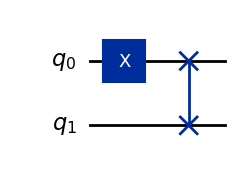

SWAP Statevector: [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
Probabilities: {np.str_('10'): np.float64(1.0)}


In [10]:
# Create a two-qubit circuit
qc_swap = QuantumCircuit(2)

# Prepare the |01> state
qc_swap.x(0)

# Exchange the states of both qubits
qc_swap.swap(0, 1)

# Display the circuit
display(qc_swap.draw("mpl"))

# Show the output state
state_swap = Statevector.from_instruction(qc_swap)

print("SWAP Statevector:", state_swap.data)
print("Probabilities:", state_swap.probabilities_dict())

In [11]:
# Display the matrix of each operation
for name, circuit in [
    ("CNOT", QuantumCircuit(2)),
    ("Controlled Phase", QuantumCircuit(2)),
    ("SWAP", QuantumCircuit(2))
]:
    if name == "CNOT":
        circuit.cx(0, 1)
    elif name == "Controlled Phase":
        circuit.cp(np.pi, 0, 1)
    else:
        circuit.swap(0, 1)

    print(f"\n{name} Matrix:")
    print(np.round(Operator(circuit).data, 3))


CNOT Matrix:
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]]

Controlled Phase Matrix:
[[ 1.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  1.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  1.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j -1.+0.j]]

SWAP Matrix:
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]]


CNOT Counts: {np.str_('11'): np.int64(1024)}


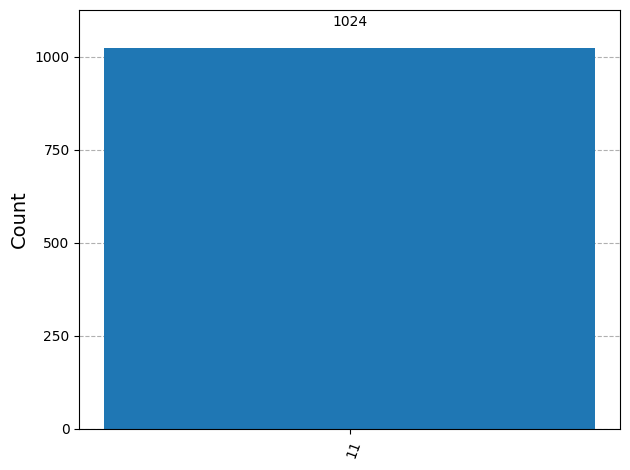

Controlled Phase Counts: {np.str_('11'): np.int64(1024)}


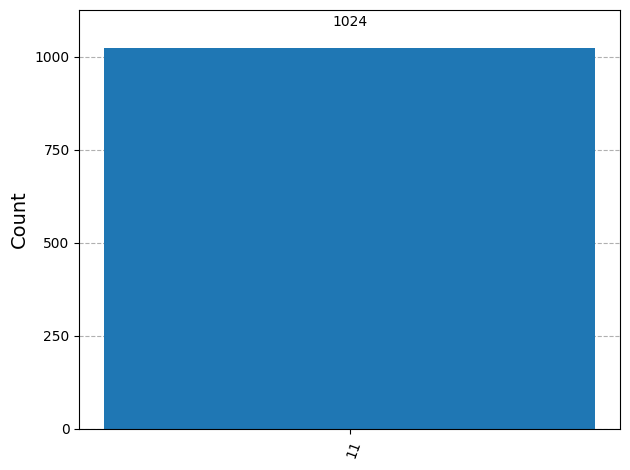

SWAP Counts: {np.str_('10'): np.int64(1024)}


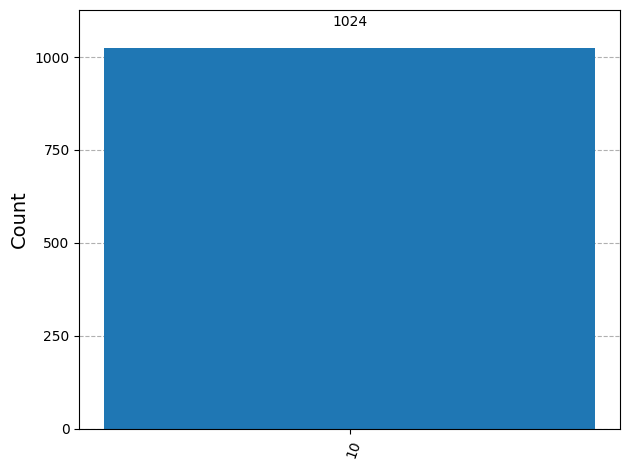

In [12]:
# Measure each output state 1024 times
for name, state in [
    ("CNOT", state_cnot),
    ("Controlled Phase", state_phase),
    ("SWAP", state_swap)
]:
    state.seed(42)
    counts = state.sample_counts(shots=1024)

    print(f"{name} Counts:", counts)
    display(plot_histogram(counts))